## 1. Load the shared splits and preprocessing pipeline
Load `data/splits/` and `models/preprocessor_unfitted.joblib` from notebook 04. The test set is used only once, in Section 6.

In [1]:
from pathlib import Path
import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import xgboost
except ImportError:
    %pip install -q xgboost
    import xgboost
from xgboost import XGBClassifier

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)
from scipy.stats import randint, uniform, loguniform

RANDOM_STATE = 42   # same seed as notebook 04

# Use an explicit project path, or discover it from this notebook's directory.
project_override = os.environ.get('HOTEL_BOOKING_ROOT')
if project_override:
    ROOT = Path(project_override).expanduser().resolve()
else:
    ROOT = next(
        (p for p in [Path.cwd(), *Path.cwd().parents]
         if (p / 'data/raw/hotel_bookings.csv').is_file()),
        None,
    )
    if ROOT is None:
        try:
            from google.colab import drive
        except ImportError:
            raise FileNotFoundError(
                'Cannot locate the project. Open the notebook inside the project '
                'folder or set HOTEL_BOOKING_ROOT to that folder.'
            ) from None
        drive.mount('/content/drive')
        ROOT = Path('/content/drive/MyDrive/hotel-booking-cancellation')
print('Project folder:', ROOT)

SPLIT_DIR = ROOT / 'data/splits'
MODEL_DIR = ROOT / 'models'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for f in ['X_train.csv', 'X_test.csv', 'y_train.csv', 'y_test.csv']:
    if not (SPLIT_DIR / f).is_file():
        raise FileNotFoundError(f'Missing {SPLIT_DIR / f}. Run notebooks/04 preprocessing first.')

X_train = pd.read_csv(SPLIT_DIR / 'X_train.csv', dtype={'agent': str})
X_test = pd.read_csv(SPLIT_DIR / 'X_test.csv', dtype={'agent': str})
y_train = pd.read_csv(SPLIT_DIR / 'y_train.csv')['is_canceled']
y_test = pd.read_csv(SPLIT_DIR / 'y_test.csv')['is_canceled']

print('xgboost:', xgboost.__version__, '| scikit-learn:', sklearn.__version__, '| pandas:', pd.__version__)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print(f'Cancelled in train: {y_train.mean():.2%} | in test: {y_test.mean():.2%}')

Mounted at /content/drive
Project folder: /content/drive/MyDrive/hotel-booking-cancellation
xgboost: 3.4.1 | scikit-learn: 1.6.1 | pandas: 2.2.3
Train: (69777, 28) | Test: (17445, 28)
Cancelled in train: 27.53% | in test: 27.53%


In [2]:
config = json.loads((MODEL_DIR / 'preprocessing_config.json').read_text())

def build_preprocessor_from_config(cfg):
    '''Same structure as build_preprocessor() in notebook 04, using the saved feature lists.'''
    numeric_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    categorical_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                 min_frequency=cfg['min_category_count'],
                                 sparse_output=False)),
    ])
    return ColumnTransformer(
        transformers=[
            ('num', numeric_pipeline, cfg['numerical_features']),
            ('bin', 'passthrough', cfg['binary_features']),
            ('cat', categorical_pipeline, cfg['categorical_features']),
        ],
        remainder='drop',
        verbose_feature_names_out=True,
    ).set_output(transform='pandas')

try:
    with warnings.catch_warnings():
        warnings.simplefilter('error')   # treat a version-mismatch warning as a failure
        preprocessor = joblib.load(MODEL_DIR / 'preprocessor_unfitted.joblib')
    print('Loaded preprocessor_unfitted.joblib')
except Exception as e:
    print(f'Could not load the .joblib cleanly ({type(e).__name__}); rebuilding from preprocessing_config.json')
    preprocessor = build_preprocessor_from_config(config)

expected = config['numerical_features'] + config['binary_features'] + config['categorical_features']
missing = set(expected) - set(X_train.columns)
assert not missing, f'Split files are missing columns the preprocessor needs: {missing}. Re-run notebook 04.'
print('Predictor columns used:', len(expected))

Loaded preprocessor_unfitted.joblib
Predictor columns used: 28


## 2. How XGBoost works
**Question:** How does XGBoost differ from the other three models?
- **Logistic Regression:** one weighted formula.
- **Decision Tree:** one tree of yes/no questions.
- **Random Forest:** many independent trees that vote.
- **XGBoost (gradient boosting):** trees are built one after another; each new tree corrects the errors of the previous trees. `learning_rate` controls how much each tree corrects, `n_estimators` is the number of trees, `max_depth` limits each tree's complexity, and `gamma`, `min_child_weight` and `reg_lambda` are regularisation settings that reduce overfitting.

Every model is wrapped as `Pipeline([("preprocess", preprocessor), ("model", estimator)])`, so preprocessing is re-fitted inside each cross-validation fold using training data only.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
           'f1': 'f1', 'roc_auc': 'roc_auc'}

def make_pipeline(model):
    return Pipeline([('preprocess', clone(preprocessor)), ('model', model)])

def cv_scores(pipe, name):
    '''5-fold cross-validation on the TRAINING set only.'''
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING,
                         return_train_score=True, n_jobs=1)
    row = {'model': name}
    for m in SCORING:
        row[f'val_{m}'] = res[f'test_{m}'].mean()
    row['train_roc_auc'] = res['train_roc_auc'].mean()
    row['roc_auc_gap (train - val)'] = row['train_roc_auc'] - row['val_roc_auc']
    return row

## 3. Baseline XGBoost and class imbalance
**Question:** How does a default XGBoost perform, and does weighting the minority class help? Only ~27.5% of bookings are cancelled. `scale_pos_weight = not cancelled / cancelled` (≈ 2.6) gives cancelled bookings more weight during training, which usually raises recall and lowers precision.

In [4]:
SCALE_POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()
print(f'scale_pos_weight = {SCALE_POS_WEIGHT:.2f}')

# Use the GPU automatically if Colab has one (Runtime -> Change runtime type -> T4 GPU)
import shutil, subprocess
USE_GPU = shutil.which('nvidia-smi') is not None and subprocess.run(
    ['nvidia-smi'], capture_output=True).returncode == 0
warnings.filterwarnings('ignore', message='.*mismatched devices.*')   # harmless GPU/CPU data warning
base_params = dict(eval_metric='logloss', tree_method='hist', n_jobs=-1, random_state=RANDOM_STATE)
if USE_GPU:
    base_params['device'] = 'cuda'
print('Training on:', 'GPU' if USE_GPU else 'CPU')

t0 = time.time()
cv_rows = [
    cv_scores(make_pipeline(XGBClassifier(**base_params)), 'XGBoost default'),
    cv_scores(make_pipeline(XGBClassifier(scale_pos_weight=SCALE_POS_WEIGHT, **base_params)),
              'XGBoost default + scale_pos_weight'),
]
print(f'Done in {time.time() - t0:.0f}s')
display(pd.DataFrame(cv_rows).set_index('model').round(3))

scale_pos_weight = 2.63
Training on: GPU
Done in 41s


,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,train_roc_auc,roc_auc_gap (train - val)
model,,,,,,,
XGBoost default,0.845,0.744,0.664,0.702,0.909,0.937,0.028
XGBoost default + scale_pos_weight,0.815,0.620,0.848,0.716,0.909,0.938,0.030


## 4. Hyperparameter tuning
**Question:** Which XGBoost settings give the best validation ROC-AUC? `RandomizedSearchCV` tests `N_ITER` random combinations (15 on GPU, 10 on CPU) with 3-fold CV on the training set. ROC-AUC is used for selection because it does not depend on a threshold and handles class imbalance well.

Runtime: about 3–5 minutes on a T4 GPU, about 10 minutes on CPU. The GPU is used automatically when available (**Runtime → Change runtime type → T4 GPU**). Keep the Colab tab open while it runs.

In [5]:
# Faster tuning: fewer settings + 3-fold CV inside the search (final checks still use 5-fold)
N_ITER = 15 if USE_GPU else 10
TUNING_FOLDS = 3
tuning_cv = StratifiedKFold(n_splits=TUNING_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print(f'Tuning {N_ITER} settings x {TUNING_FOLDS} folds = {N_ITER * TUNING_FOLDS} fits')

param_distributions = {
    'model__n_estimators': randint(200, 800),         # number of trees
    'model__learning_rate': loguniform(0.02, 0.3),    # contribution of each tree
    'model__max_depth': randint(3, 11),               # depth of each tree
    'model__min_child_weight': randint(1, 10),        # minimum data per leaf
    'model__subsample': uniform(0.6, 0.4),            # share of rows per tree (0.6-1.0)
    'model__colsample_bytree': uniform(0.5, 0.5),     # share of columns per tree (0.5-1.0)
    'model__gamma': uniform(0, 5),                    # minimum gain to split
    'model__reg_lambda': loguniform(0.1, 10),         # L2 regularisation
}

search = RandomizedSearchCV(
    estimator=make_pipeline(XGBClassifier(scale_pos_weight=SCALE_POS_WEIGHT, **base_params)),
    param_distributions=param_distributions, n_iter=N_ITER, scoring='roc_auc', cv=tuning_cv,
    return_train_score=True, random_state=RANDOM_STATE, n_jobs=1, verbose=3,   # prints a line per fit
)
t0 = time.time()
search.fit(X_train, y_train)
print(f'Tuning finished in {(time.time() - t0) / 60:.1f} min | best CV ROC-AUC: {search.best_score_:.4f}')

best_params = {k.replace('model__', ''): (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v))
               for k, v in search.best_params_.items()}
display(pd.Series(best_params, name='best value').to_frame())
pd.DataFrame(search.cv_results_).to_csv(RESULTS_DIR / 'xgboost_tuning_results.csv', index=False)

Tuning 15 settings x 3 folds = 45 fits
Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV 1/3] END model__colsample_bytree=0.6872700594236812, model__gamma=4.75357153204958, model__learning_rate=0.14518497439122724, model__max_depth=7, model__min_child_weight=5, model__n_estimators=321, model__reg_lambda=0.2051110418843398, model__subsample=0.6232334448672797;, score=(train=0.943, test=0.907) total time=   3.6s
[CV 2/3] END model__colsample_bytree=0.6872700594236812, model__gamma=4.75357153204958, model__learning_rate=0.14518497439122724, model__max_depth=7, model__min_child_weight=5, model__n_estimators=321, model__reg_lambda=0.2051110418843398, model__subsample=0.6232334448672797;, score=(train=0.941, test=0.909) total time=   2.3s
[CV 3/3] END model__colsample_bytree=0.6872700594236812, model__gamma=4.75357153204958, model__learning_rate=0.14518497439122724, model__max_depth=7, model__min_child_weight=5, model__n_estimators=321, model__reg_lambda=0.2051110418843398, mo

,best value
colsample_bytree,0.6180
gamma,1.2803
learning_rate,0.0223
max_depth,9.0000
min_child_weight,3.0000
n_estimators,774.0000
reg_lambda,6.1877
subsample,0.7901


## 5. Overfitting check
**Question:** Does the tuned model generalise? Compare cross-validated scores for the default, weighted and tuned models. A gap below about 0.05 between training and validation ROC-AUC indicates the model is not memorising the training data.

In [6]:
best_pipe = search.best_estimator_
cv_rows.append(cv_scores(clone(best_pipe), 'XGBoost tuned'))
cv_table = pd.DataFrame(cv_rows).set_index('model')
display(cv_table.round(3))
cv_table.to_csv(RESULTS_DIR / 'xgboost_cv_comparison.csv')

,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,train_roc_auc,roc_auc_gap (train - val)
model,,,,,,,
XGBoost default,0.845,0.744,0.664,0.702,0.909,0.937,0.028
XGBoost default + scale_pos_weight,0.815,0.620,0.848,0.716,0.909,0.938,0.030
XGBoost tuned,0.821,0.629,0.852,0.724,0.914,0.947,0.033


## 6. Final evaluation on the test set
**Question:** How well does the tuned XGBoost predict cancellations on unseen data? Refit the tuned pipeline on the full training set, then evaluate once on the test set with the default 0.5 threshold (same threshold for every model, so the comparison is fair).

In [7]:
final_model = clone(best_pipe).fit(X_train, y_train)
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
}
metrics_table = pd.DataFrame(metrics, index=['XGBoost']).round(4)
display(metrics_table)

print(classification_report(y_test, y_pred, target_names=['Not cancelled', 'Cancelled'], digits=4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
XGBoost,0.8276,0.6371,0.868,0.7348,0.9202


               precision    recall  f1-score   support

Not cancelled     0.9419    0.8122    0.8723     12643
    Cancelled     0.6371    0.8680    0.7348      4802

     accuracy                         0.8276     17445
    macro avg     0.7895    0.8401    0.8035     17445
 weighted avg     0.8580    0.8276    0.8344     17445



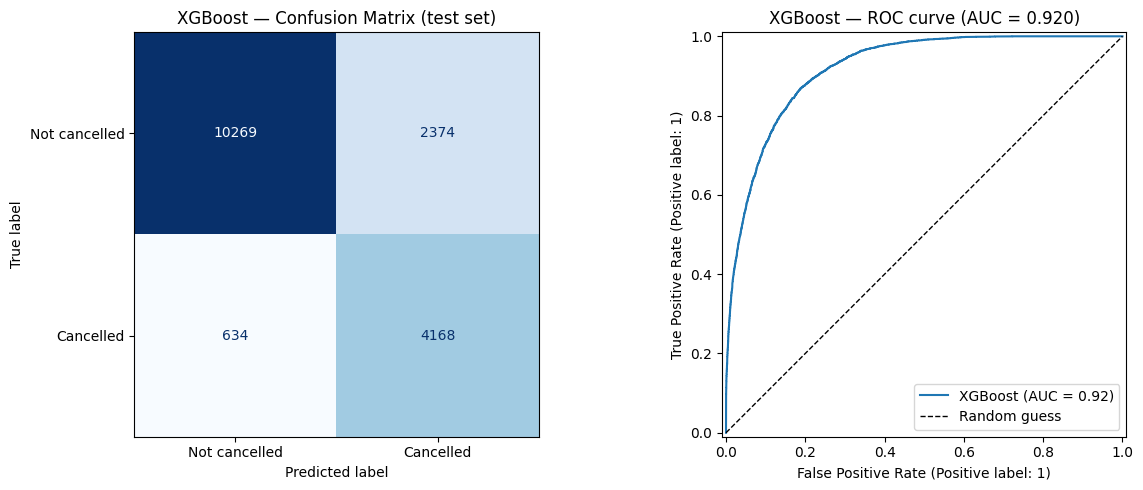

True negatives  (correctly predicted not cancelled): 10,269
False positives (predicted cancel, guest arrived):    2,374
False negatives (missed cancellations):              634
True positives  (correctly predicted cancelled):     4,168


In [8]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=['Not cancelled', 'Cancelled']).plot(
    ax=axes[0], cmap='Blues', colorbar=False, values_format='d')
axes[0].set_title('XGBoost — Confusion Matrix (test set)')
RocCurveDisplay.from_predictions(y_test, y_proba, name='XGBoost', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, label='Random guess')
axes[1].set_title(f'XGBoost — ROC curve (AUC = {metrics["ROC-AUC"]:.3f})')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'xgboost_confusion_matrix_roc.png', dpi=150)
plt.show()

print(f'True negatives  (correctly predicted not cancelled): {tn:,}')
print(f'False positives (predicted cancel, guest arrived):    {fp:,}')
print(f'False negatives (missed cancellations):              {fn:,}')
print(f'True positives  (correctly predicted cancelled):     {tp:,}')

## 7. Feature importance
**Question:** Which features does XGBoost rely on most? Gain importance shows how much each encoded feature improved the trees. Importance shows what the model uses, not what causes cancellations.

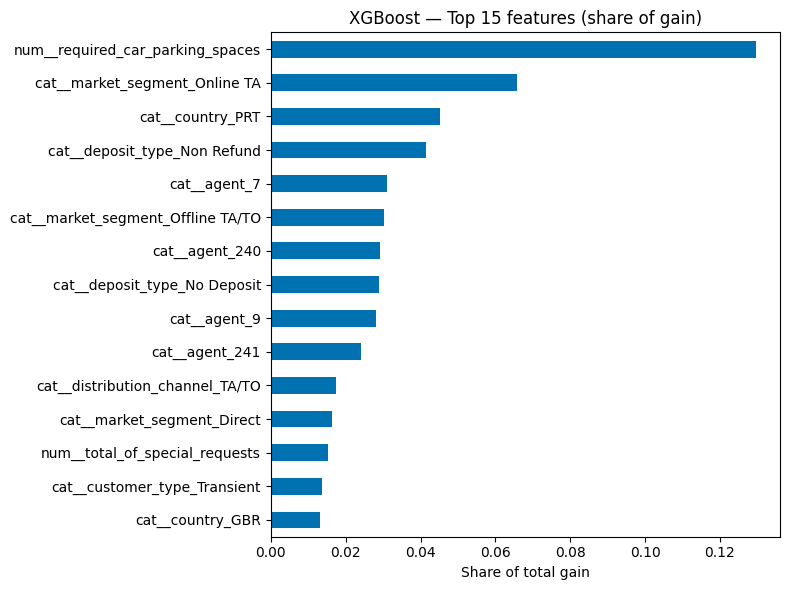

In [9]:
booster = final_model.named_steps['model']
gain = pd.Series(booster.get_booster().get_score(importance_type='gain'))
gain = (gain / gain.sum()).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
gain[::-1].plot.barh(color='#0072B2')
plt.title('XGBoost — Top 15 features (share of gain)')
plt.xlabel('Share of total gain')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'xgboost_feature_importance.png', dpi=150)
plt.show()

## 8. Save model and results
Save the fitted model and the metrics so the final comparison can read them.

In [10]:
joblib.dump(final_model, MODEL_DIR / 'xgboost_model.joblib')

result = {
    'model': 'XGBoost',
    'threshold': 0.5,
    'best_params': best_params,
    'cv_roc_auc': float(cv_table.loc['XGBoost tuned', 'val_roc_auc']),
    'test_metrics': {k: float(v) for k, v in metrics.items()},
    'confusion_matrix': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)},
}
(RESULTS_DIR / 'xgboost_metrics.json').write_text(json.dumps(result, indent=2))
metrics_table.to_csv(RESULTS_DIR / 'xgboost_metrics.csv')

for p in [MODEL_DIR / 'xgboost_model.joblib', RESULTS_DIR / 'xgboost_metrics.json',
          RESULTS_DIR / 'xgboost_metrics.csv', RESULTS_DIR / 'xgboost_confusion_matrix_roc.png',
          RESULTS_DIR / 'xgboost_feature_importance.png', RESULTS_DIR / 'xgboost_cv_comparison.csv']:
    print(' ', p)

  /content/drive/MyDrive/hotel-booking-cancellation/models/xgboost_model.joblib
  /content/drive/MyDrive/hotel-booking-cancellation/results/xgboost_metrics.json
  /content/drive/MyDrive/hotel-booking-cancellation/results/xgboost_metrics.csv
  /content/drive/MyDrive/hotel-booking-cancellation/results/xgboost_confusion_matrix_roc.png
  /content/drive/MyDrive/hotel-booking-cancellation/results/xgboost_feature_importance.png
  /content/drive/MyDrive/hotel-booking-cancellation/results/xgboost_cv_comparison.csv


## 9. Model comparison
**Question:** How does XGBoost compare with the other three models? Each modelling notebook should save `results/<model>_metrics.json` in the same format as Section 8 (`logistic_regression`, `decision_tree`, `random_forest`, `xgboost`). This cell builds the comparison table from whichever files exist.

In [11]:
rows, cms = [], {}
for p in sorted(RESULTS_DIR.glob('*_metrics.json')):
    r = json.loads(p.read_text())
    rows.append({'model': r['model'], **r['test_metrics']})
    if 'confusion_matrix' in r:
        cms[r['model']] = r['confusion_matrix']

comparison = pd.DataFrame(rows).set_index('model').sort_values('ROC-AUC', ascending=False)
display(comparison.round(4))
comparison.to_csv(RESULTS_DIR / 'model_comparison.csv')

waiting = {'Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost'} - set(comparison.index)
if waiting:
    print('Waiting for results from:', ', '.join(sorted(waiting)))
else:
    comparison.plot.bar(figsize=(11, 4.5), rot=0)
    plt.ylim(0, 1); plt.ylabel('Score'); plt.title('Model comparison on the test set')
    plt.legend(loc='lower right', ncol=5); plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'model_comparison.png', dpi=150); plt.show()

,Accuracy,Precision,Recall,F1-score,ROC-AUC
model,,,,,
XGBoost,0.8276,0.6371,0.868,0.7348,0.9202


Waiting for results from: Decision Tree, Logistic Regression, Random Forest


## 10. XGBoost summary
**Findings:** Record the final XGBoost decisions.

In [12]:
summary = pd.DataFrame([
    ('Data', 'Shared splits from notebook 04', 'Same train/test rows as every other model'),
    ('Preprocessing', 'Shared unfitted pipeline inside the model pipeline', 'Fitted on training folds only; no leakage'),
    ('Class imbalance', f'scale_pos_weight = {SCALE_POS_WEIGHT:.2f}', 'Gives more weight to the minority (cancelled) class'),
    ('Tuning', f'RandomizedSearchCV, {N_ITER} settings, {TUNING_FOLDS}-fold CV, ROC-AUC', 'Efficient search over eight hyperparameters'),
    ('Overfitting control', 'Regularisation settings tuned; train/validation gap checked', 'Default XGBoost overfits'),
    ('Threshold', '0.5', 'Same threshold for all four models'),
    ('Evaluation', 'Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix', 'Test set used once'),
], columns=['Item', 'Decision', 'Reason'])
display(summary)

,Item,Decision,Reason
0,Data,Shared splits from notebook 04,Same train/test rows as every other model
1,Preprocessing,Shared unfitted pipeline inside the model pipe...,Fitted on training folds only; no leakage
2,Class imbalance,scale_pos_weight = 2.63,Gives more weight to the minority (cancelled) ...
3,Tuning,"RandomizedSearchCV, 15 settings, 3-fold CV, RO...",Efficient search over eight hyperparameters
4,Overfitting control,Regularisation settings tuned; train/validatio...,Default XGBoost overfits
5,Threshold,0.5,Same threshold for all four models
6,Evaluation,"Accuracy, Precision, Recall, F1, ROC-AUC, Conf...",Test set used once
